In [1]:
import mplhep as hep
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot as ur

from utils.labels import (
    luminosity
)

In [104]:
channel_US = "VBF"
bkg_file = "../root_io/tuples/BDT_score/" + channel_US + "/BFull_SNottH/background_Combined.root"
#bkg_file = "../root_io/tuples/DY_Combined_tuples.root"
sig_file = "../root_io/tuples/BDT_score/" + channel_US + "/BFull_SNottH/signal_Combined.root"

In [105]:
with ur.open(sig_file+":tree_output") as file:
    print(file.keys())

['gen_weight', 'pileup_weight', 'pileup_weight_up', 'pileup_weight_down', 'scale_factor', 'weight', 'weight_no_lumi', 'rho', 'PV', 'n_SoftJet_pt2', 'n_SoftJet_pt5', 'n_SoftJet_pt10', 'HT', 'HT_pt2', 'HT_pt5', 'HT_pt10', 'is_ggH_category', 'is_VBF_category', 'mc_campaign', 'channel', 'diMuon_mass', 'diMuon_bsConstrainedMass', 'diMuon_pt', 'diMuon_bsConstrainedPt', 'diMuon_phi', 'diMuon_eta', 'diMuon_rapidity', 'PuppiMET_phi', 'PuppiMET_pt', 'PuppiMET_sumEt', 'mu1_pt_mass_ratio', 'mu2_pt_mass_ratio', 'mu1_bsConstrainedPt_mass_ratio', 'mu2_bsConstrainedPt_mass_ratio', 'mu1_eta', 'mu2_eta', 'mu1_pt', 'mu2_pt', 'mu1_bsConstrainedPt', 'mu2_bsConstrainedPt', 'mu1_ptErr', 'mu2_ptErr', 'mu1_bsConstrainedPtErr', 'mu2_bsConstrainedPtErr', 'mu1_dz', 'mu2_dz', 'mu1_dzErr', 'mu2_dzErr', 'phi_CS', 'cos_theta_CS', 'relative_diMuon_mass_error', 'relative_diMuon_bsConstrainedMass_error', 'n_jet', 'n_bjet', 'n_bjet_Loose', 'leading_jet_pt', 'leading_jet_eta', 'leading_jet_btagPNetB', 'subleading_jet_pt',

In [106]:
bkg_tree = ur.open(bkg_file+":tree_output")
sig_tree = ur.open(sig_file+":tree_output")

In [107]:
diMuon_mass_bsC_bkg = bkg_tree["diMuon_bsConstrainedMass"].array(library='np')
bkg_weight = bkg_tree["weight"].array(library='np')
diMuon_mass_bsC_sig = sig_tree["diMuon_bsConstrainedMass"].array(library='np')
sig_weight = bkg_tree["weight"].array(library='np')
BDT_bkg = bkg_tree["BDT_"+channel_US].array(library='np')
BDT_sig = sig_tree["BDT_"+channel_US].array(library='np')

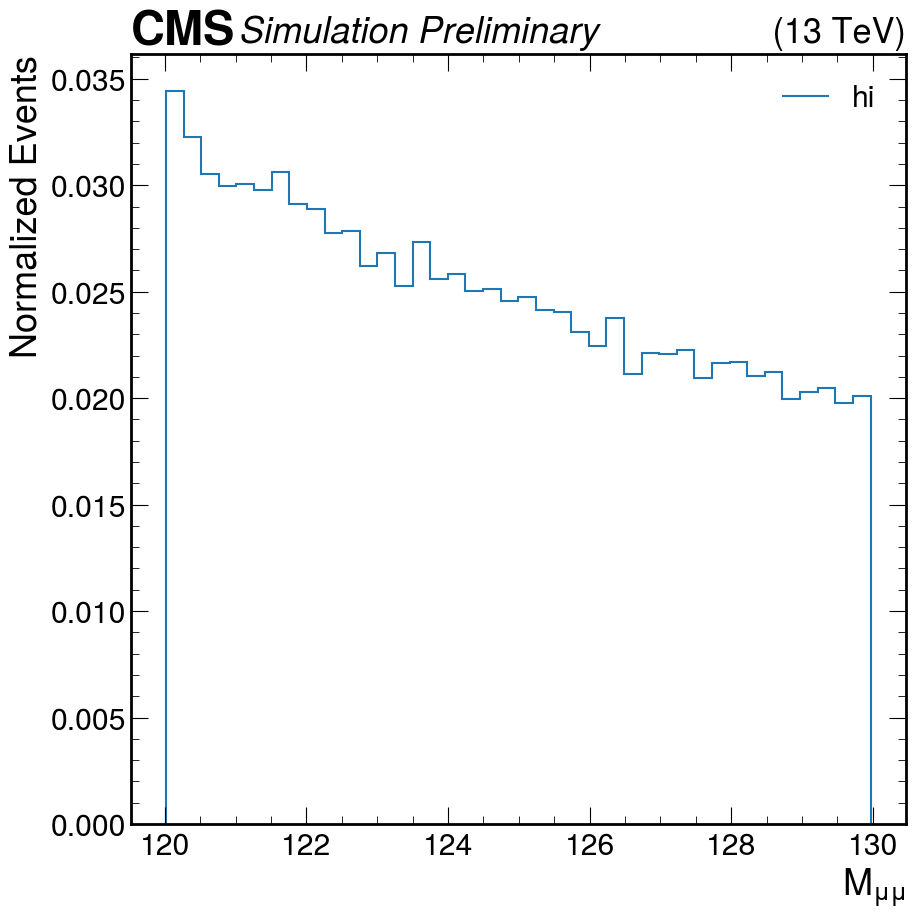

In [108]:
mask = (BDT_bkg > 0) & (BDT_bkg < 1) & (diMuon_mass_bsC_bkg > 120) & (diMuon_mass_bsC_bkg < 130)
hep.style.use("CMS")

counts, bins = np.histogram(diMuon_mass_bsC_bkg[mask], bins=40, weights=bkg_weight[mask])
counts = counts / counts.sum()
fig, ax = plt.subplots()

hep.histplot(counts, bins=bins, ax=ax, label="hi")
hep.cms.label("Preliminary", data=False, com=13) 
ax.set_xlabel('$M_{\mu\mu}$')
ax.set_ylabel('Normalized Events')
ax.legend()

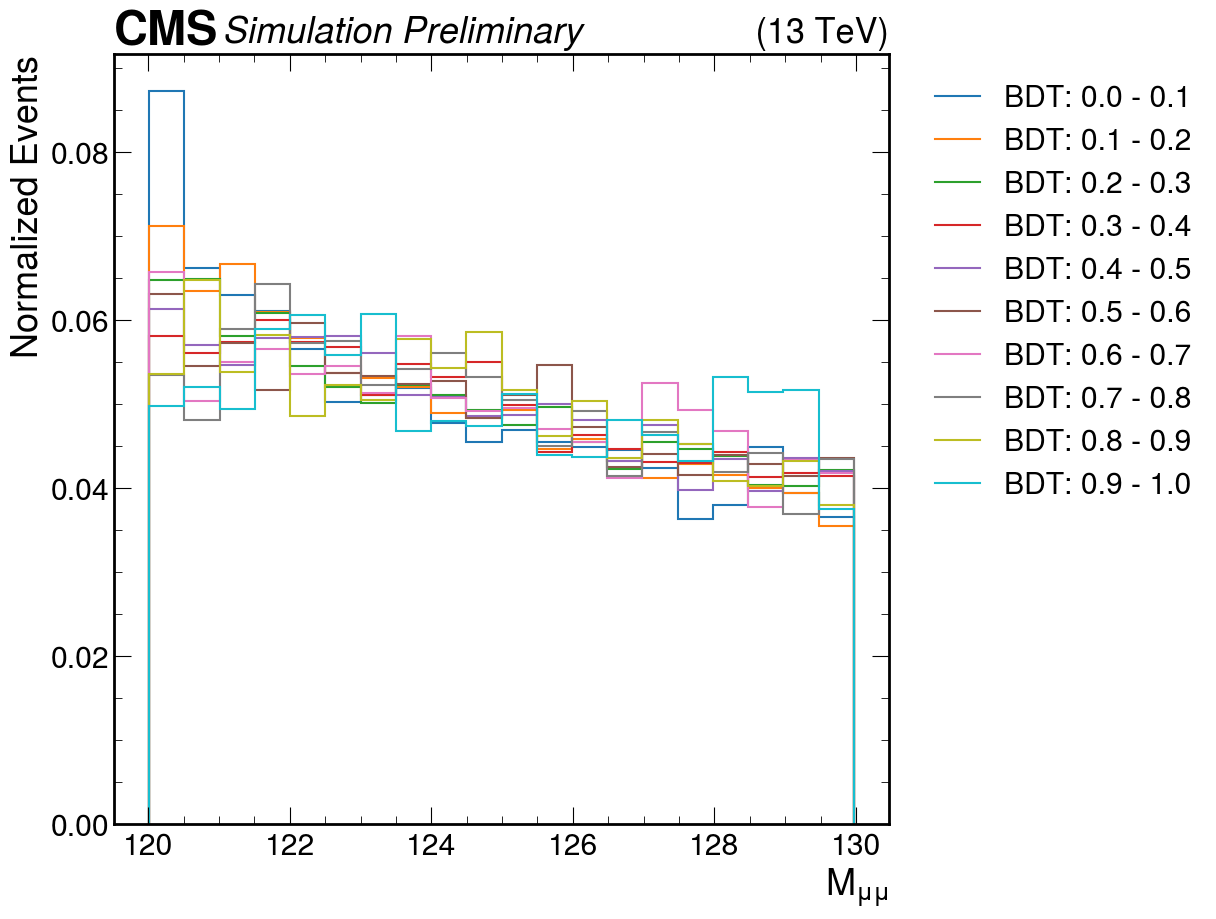

In [109]:
bdt_divisions = 10
mass_low = 120
mass_high = 130
hep.style.use("CMS")

fig, ax = plt.subplots()

hep.cms.label("Preliminary", data=False, com=13) 
ax.set_xlabel('$M_{\mu\mu}$')
ax.set_ylabel('Normalized Events')

for bdt_cut in np.linspace(0,0.9,bdt_divisions):
    bdt_spacing = 1/bdt_divisions
    bdt_low = bdt_cut
    bdt_high = bdt_low + bdt_spacing
    
    mask = (BDT_bkg > bdt_low) & (BDT_bkg < bdt_high) & (diMuon_mass_bsC_bkg > mass_low) & (diMuon_mass_bsC_bkg < mass_high)
    hep.style.use("CMS")

    counts, bins = np.histogram(diMuon_mass_bsC_bkg[mask], bins=20, weights=bkg_weight[mask])
    counts = counts / counts.sum()

    hep.histplot(counts, bins=bins, ax=ax, label=f"BDT: {bdt_low:.1f} - {bdt_high:.1f}")

#ax.legend()
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
#plt.show()
plt.savefig('../plots/sculpting_study/optunaBkgVBFscuplting.png', bbox_inches="tight")
plt.savefig('../plots/sculpting_study/optunaBkgVBFscuplting.pdf', bbox_inches="tight")